# Syllable use along the first discriminants (supplementary)

The syllable composition over the time-warped trial (fig_segmentation panel K / `fig_syllable_use_per_mouse`), drawn along each of the first five discriminants: for LD*k* (row), the 260 sessions are binned by their LD*k* score into `N_BINS` bins (columns, low → high; 5 by default): equal-count bins by default (`BINNING = 'quantile'`), or equal-width bins over the LD's range (`'width'`; the edge bins then hold a few extreme sessions, sometimes of 1-2 mice, see the counts in the panel titles), and each panel pools all trials of the sessions in that bin. So a row shows what changes in syllable use as sessions move along that axis.

Scores: the paper's LDA embedding (`mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026`, one row per session). An LD's sign is arbitrary, so "low" and "high" only orient the row. Pooled trials: a session weighs by its trial count. Same syllable file and drawing function (`paper_style.syllable_histogram`) as fig_segmentation, so the panels are directly comparable with K.

In [1]:
import sys, pathlib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from datetime import date

FIGDIR = pathlib.Path.cwd().resolve()
while not (FIGDIR / 'fig_layout.py').exists() and FIGDIR != FIGDIR.parent:
    FIGDIR = FIGDIR / 'figure_generation' if (FIGDIR / 'figure_generation').exists() else FIGDIR.parent
PI = FIGDIR.parent
for p in [str(PI), str(FIGDIR)]:
    if p not in sys.path:
        sys.path.insert(0, p)
try:
    import numpy._core.numeric  # noqa: F401
except ModuleNotFoundError:     # the LDA file was pickled under numpy 2
    import numpy.core.numeric, numpy.core.multiarray
    sys.modules['numpy._core.numeric'], sys.modules['numpy._core.multiarray'] = np.core.numeric, np.core.multiarray
import paper_style as ps
import fig_layout as fl
ps.use('paper')
ps.use_paw_states('uniform')
FIG = 'fig_syllable_use_along_lds'

SYLLABLE_FILE = next(f for f in [PI / 'data' / '8_k_10_bin_syllables_02-10-2026',                  # fig_segmentation's
                                 PI / 'clustering' / 'data_files' / '8_k_10_bin_syllables_02-10-2026'] if f.exists())
LDA_FILE = PI / 'clustering' / 'data_files' / 'mouse_LDA_5_bins_raw_shrink0.5_wmouse_360_02-10-2026'
TEXTURE = True          # whisk / lick hatching, as panel K; False = paw colour only (cleaner at this size)
N_LDS = 5               # rows: LD1 ... LD5
N_BINS = 5              # columns: sessions binned along each LD, low -> high
BINNING = 'quantile'    # 'width': equal-width bins over each LD's range (edge bins hold few sessions)
                        # 'quantile': equal-count bins (fifths)
EPOCHS = ps.EPOCH_NAMES

paper_style: paper mode, spines=lb, font 8 pt, panels 3.4x2.4 in, save 400 dpi


## Sessions binned along each LD

In [2]:
lda = pd.read_pickle(LDA_FILE).rename(columns={0: 'LD1'}).rename(columns={k: f'LD{k + 1}' for k in range(1, N_LDS)})
LDS = [f'LD{k}' for k in range(1, N_LDS + 1)]
seq = pd.read_parquet(SYLLABLE_FILE)
seq['session'] = seq['sample'].str[:36]
seq = seq[seq['session'].isin(lda['session'])].copy()
seq['binned_sequence'] = seq['binned_sequence'].apply(ps.paw_codes)     # -> uniform (vigor) numbering, as fig_segmentation

def codes_for(rows):
    piv = rows.pivot(index=['sample'], columns=['broader_label'], values='binned_sequence').dropna()
    return np.vstack(piv[EPOCHS].apply(lambda r: np.hstack(r), axis=1)).astype(float)

CODES_BY_SESSION = {s: codes_for(g) for s, g in seq.groupby('session')}
CODES, INFO = {}, {}
for ld in LDS:
    q = (pd.cut(lda[ld], N_BINS, labels=False) if BINNING == 'width' else pd.qcut(lda[ld], N_BINS, labels=False))
    for b in range(N_BINS):
        rows = lda[q == b]
        CODES[ld, b] = np.vstack([CODES_BY_SESSION[s] for s in rows['session'] if s in CODES_BY_SESSION])
        INFO[ld, b] = (len(rows), rows['mouse_name'].nunique(), rows[ld].min(), rows[ld].max())
print(f"{SYLLABLE_FILE.name}: {len(CODES_BY_SESSION)} sessions with syllables of {len(lda)} in the LDA")
print(pd.DataFrame({k: dict(sessions=v[0], mice=v[1], trials=len(CODES[k])) for k, v in INFO.items()}).T.to_string())

8_k_10_bin_syllables_02-10-2026: 260 sessions with syllables of 260 in the LDA
       sessions  mice  trials
LD1 0        52    13   31122
    1        52    21   34119
    2        52    23   32562
    3        52    20   31364
    4        52    16   30473
LD2 0        52    18   33781
    1        52    26   31344
    2        52    20   30317
    3        52    22   33036
    4        52    17   31162
LD3 0        52    16   31838
    1        52    23   30859
    2        52    24   31217
    3        52    26   32689
    4        52    19   33037
LD4 0        52    20   33030
    1        52    22   33145
    2        52    27   32003
    3        52    27   30444
    4        52    18   31018
LD5 0        52    25   31276
    1        52    27   30325
    2        52    30   31759
    3        52    23   33123
    4        52    19   33157


## The figure

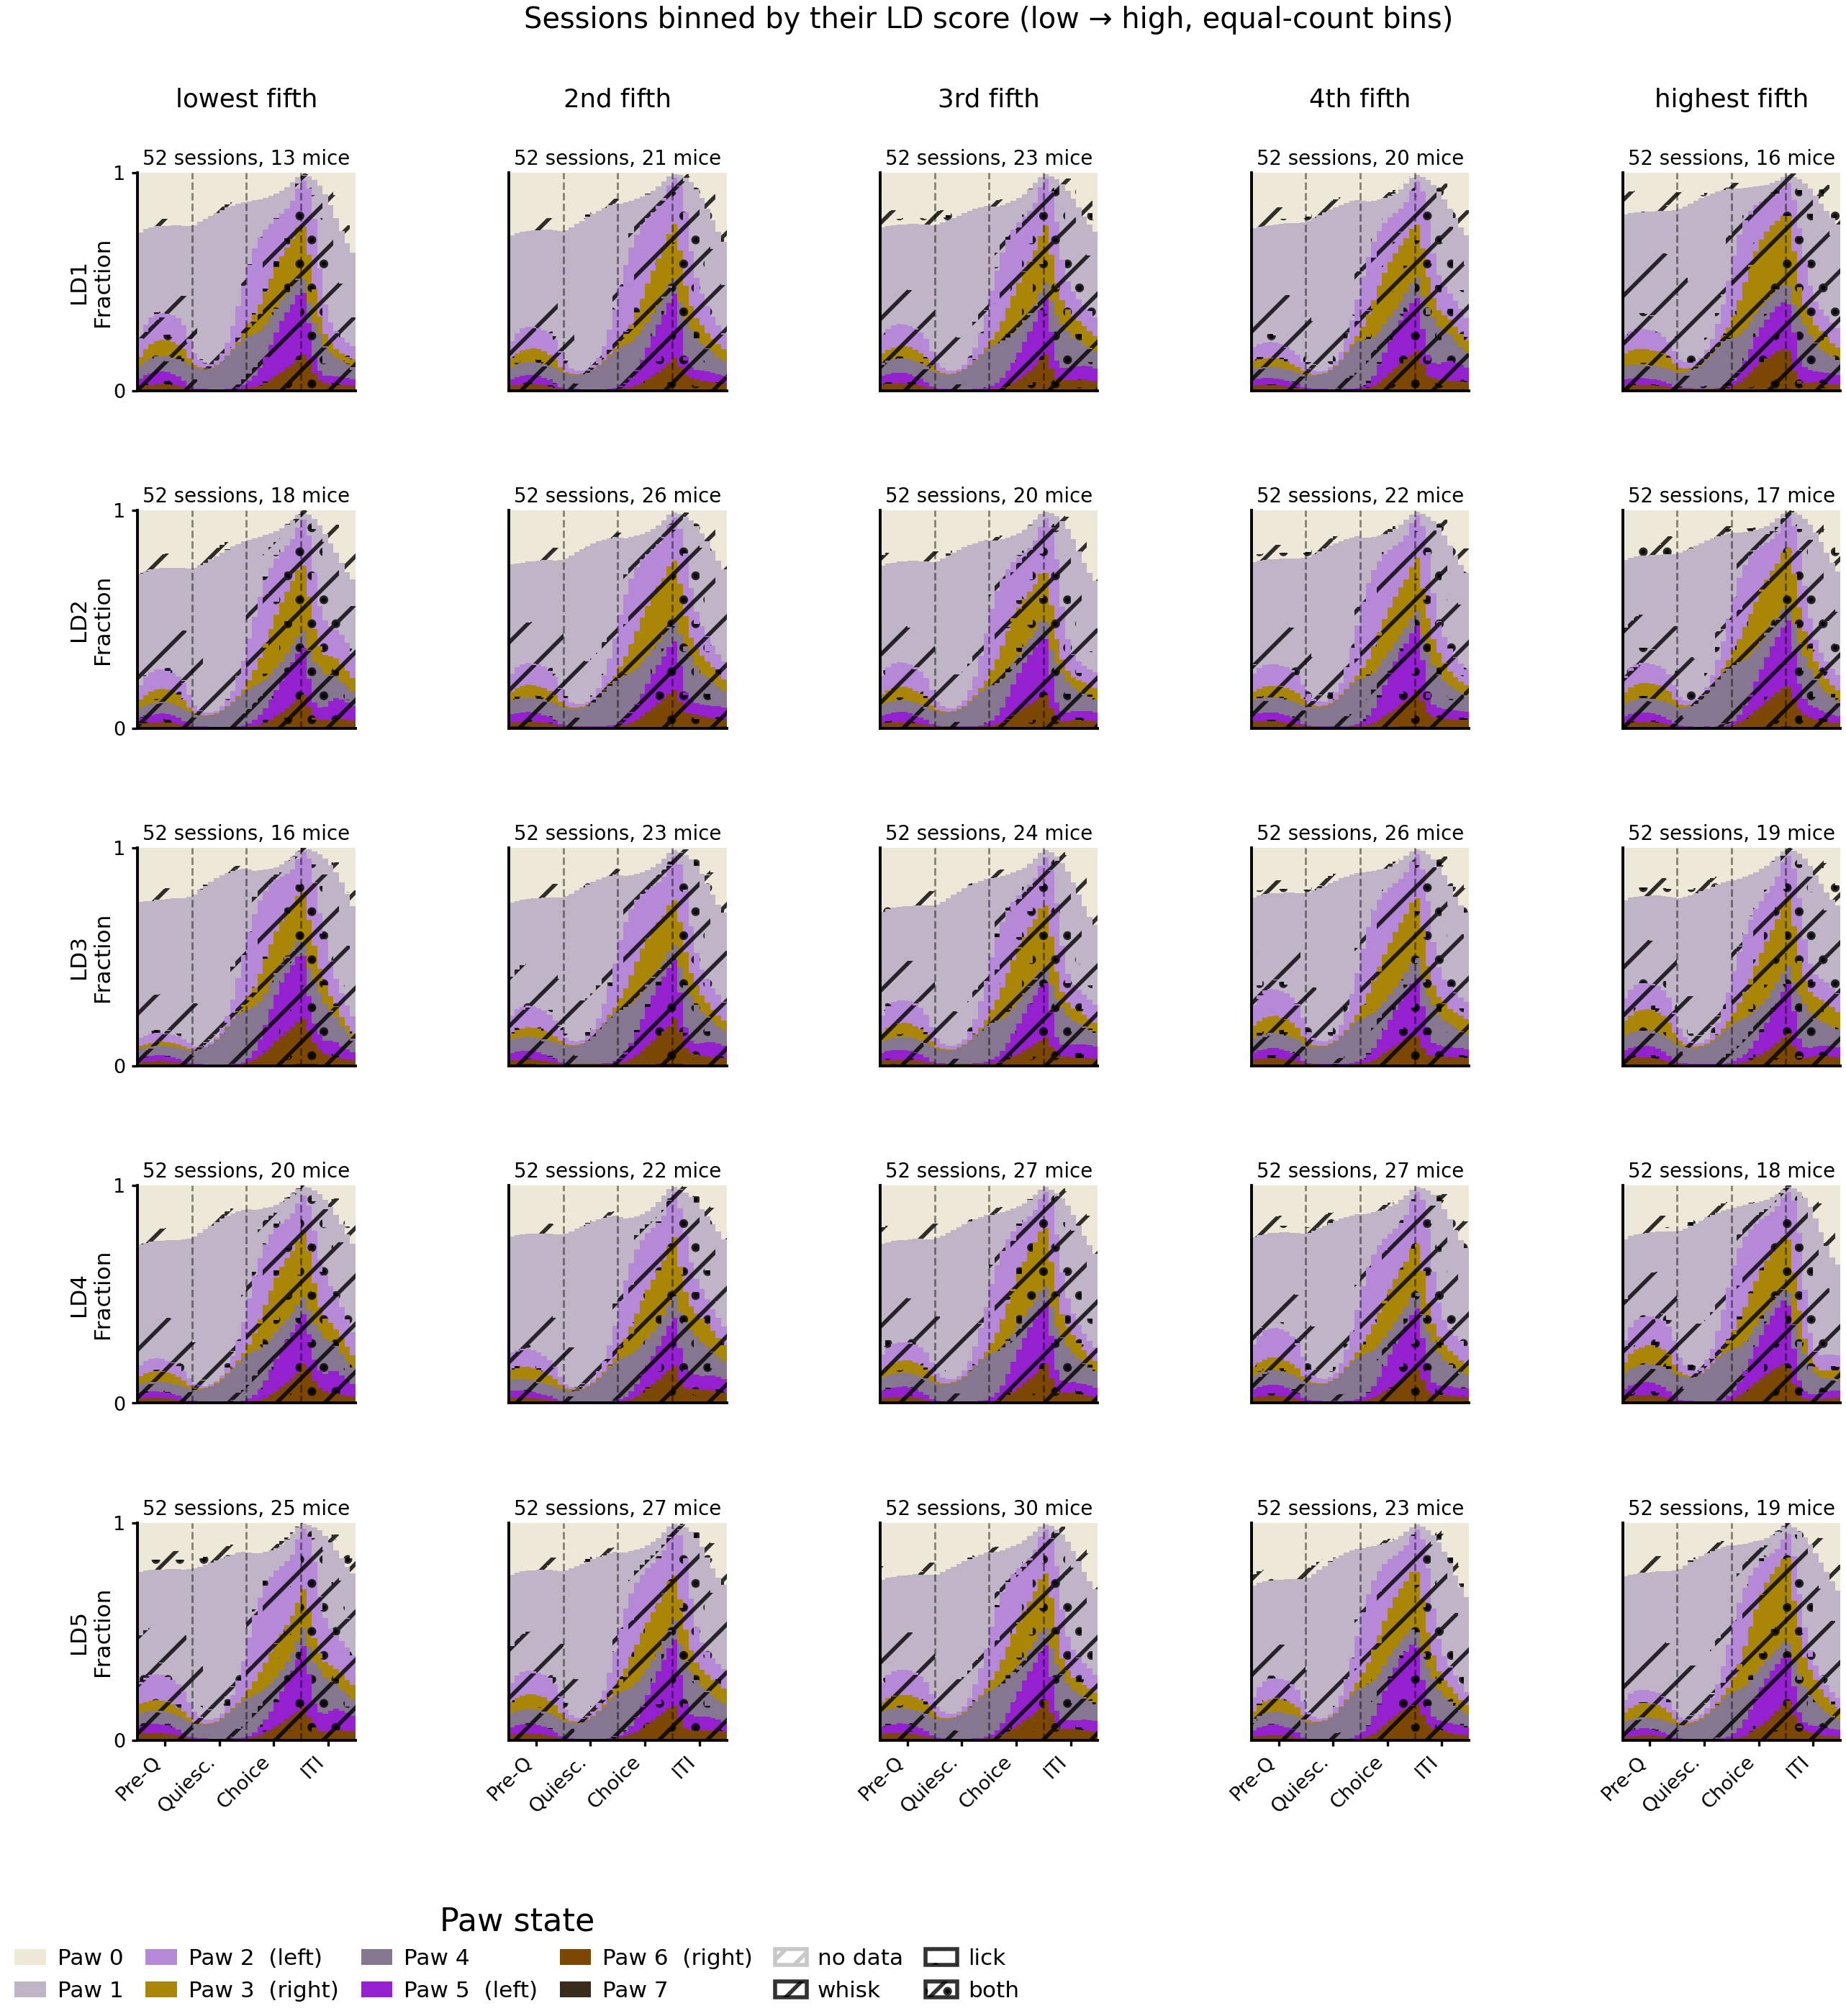

wrote figure_generation/figures/fig_syllable_use_along_lds_02-11-2026.svg


wrote figure_generation/figures/fig_syllable_use_along_lds.pdf


wrote figure_generation/figures/fig_syllable_use_along_lds.png


In [3]:
fs = plt.rcParams['font.size']
ROW_H = 1.25 * 5 / N_BINS     # square panels: rows get taller as columns get fewer
fig = plt.figure(figsize=(fl.FIG_WIDTH, ROW_H * N_LDS + 0.75))
G = fig.add_gridspec(N_LDS, N_BINS, wspace=0.12, hspace=0.55, left=0.1, right=0.99, top=0.915,
                     bottom=0.75 / (ROW_H * N_LDS + 0.75) + 0.03)
for r_, ld in enumerate(LDS):
    for b in range(N_BINS):
        ax = fig.add_subplot(G[r_, b])
        ps.syllable_histogram(CODES[ld, b], ax=ax, texture=TEXTURE, warn=False)
        ps.epoch_lines(ax, CODES[ld, b].shape[1])
        n_s, n_m, lo_, hi_ = INFO[ld, b]
        ax.set_title(f'{n_s} sessions, {n_m} mice' + (f'\n{ld} {lo_:.1f} to {hi_:.1f}' if BINNING == 'width' else ''),
                     fontsize=fs * 0.62, pad=2)
        ax.set_ylabel('')
        ax.set_box_aspect(1)
        ax.tick_params(length=1.5, labelsize=plt.rcParams['xtick.labelsize'] * 0.7)
        if b == 0:
            ax.set_yticks([0, 1])
            ax.set_ylabel(f'{ld}\nFraction', fontsize=fs * 0.7, labelpad=0)
        else:
            ax.set_yticks([])
        if r_ == N_LDS - 1:
            ax.set_xticks([5, 15, 25, 35]); ax.set_xticklabels(ps.EPOCH_SHORT, rotation=45, ha='right')
        else:
            ax.set_xticks([])
        if r_ == 0:
            names = {3: (['lowest', 'middle', 'highest'], 'third'), 5: (['lowest', '2nd', '3rd', '4th', 'highest'], 'fifth')}
            head = (f'{names[N_BINS][0][b]} {names[N_BINS][1]}' if BINNING == 'quantile' and N_BINS in names
                    else f'bin {b + 1}')
            ax.text(0.5, 1.28, head, transform=ax.transAxes, ha='center', va='bottom', fontsize=fs * 0.8)
fig.text(0.545, 0.998, 'Sessions binned by their LD score (low → high' + (', equal-width bins)' if BINNING == 'width' else ', equal-count bins)'), ha='center', va='top', fontsize=fs * 0.9)
ps.paw_legend(fig, ncol=6, hatch=TEXTURE, loc='lower left', bbox_to_anchor=(0.06, 0.0),
              fontsize=plt.rcParams['legend.fontsize'] * 0.8)
plt.show()
OUT = FIGDIR / 'figures'
for path in [OUT / f"{FIG}_{date.today().strftime('%d-%m-%Y')}.svg", OUT / f'{FIG}.pdf', OUT / f'{FIG}.png']:
    fig.savefig(path, dpi=300)
    print('wrote', path.relative_to(PI))